In [10]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import gc

BASE_DIR   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
SPLIT_NAME = "split_05_seed_55"

# Folder on disk uses this version string
FOLDER_VERSION = "v3_voltage_random10_issue_flight-removed"
# Files inside the folder use this version string (set by 02b_v2)
FILE_VERSION   = "v4_voltage_random10_cleaned"

INPUT_DIR  = BASE_DIR / f"model_ready_no_dr_{FOLDER_VERSION}" / SPLIT_NAME
OUTPUT_DIR = BASE_DIR / "model_outputs" / f"architecture_comparison_{FOLDER_VERSION}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "mps"  if torch.backends.mps.is_available()  else
    "cuda" if torch.cuda.is_available()           else
    "cpu"
)
print(f"Device     : {device}")
print(f"Input dir  : {INPUT_DIR}")
print(f"Output dir : {OUTPUT_DIR}")

# Verify files exist before running anything else
print("\nFile check:")
for prefix in ["train", "val", "test"]:
    p = INPUT_DIR / f"{prefix}_no_dr_scaled_{FILE_VERSION}_{SPLIT_NAME}.parquet"
    print(f"  {'EXISTS ✓' if p.exists() else 'MISSING ✗'}: {p.name}")

Device     : mps
Input dir  : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_issue_flight-removed/split_05_seed_55
Output dir : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/architecture_comparison_v3_voltage_random10_issue_flight-removed

File check:
  EXISTS ✓: train_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  EXISTS ✓: val_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet
  EXISTS ✓: test_no_dr_scaled_v4_voltage_random10_cleaned_split_05_seed_55.parquet


In [11]:
FEATURE_COLS = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

SEQ_LEN       = 100
STRIDE_TRAIN  = 20
STRIDE_SCORE  = 10
BATCH_SIZE    = 64
EPOCHS        = 200
PATIENCE      = 15
MAX_GRAD_NORM = 1.0
N_FEATURES    = len(FEATURE_COLS)

# Baseline from notebook 05c (LSTM-AE on split_05 before flight removal)
BASELINE_AUROC = 0.6692

print(f"Features       : {N_FEATURES}")
print(f"Sequence length: {SEQ_LEN} rows = {SEQ_LEN/10:.0f} seconds at 10 Hz")
print(f"Baseline AUROC : {BASELINE_AUROC} (LSTM-AE from 05c)")

Features       : 13
Sequence length: 100 rows = 10 seconds at 10 Hz
Baseline AUROC : 0.6692 (LSTM-AE from 05c)


In [12]:
train_path = INPUT_DIR / f"train_no_dr_scaled_{FILE_VERSION}_{SPLIT_NAME}.parquet"
val_path   = INPUT_DIR / f"val_no_dr_scaled_{FILE_VERSION}_{SPLIT_NAME}.parquet"
test_path  = INPUT_DIR / f"test_no_dr_scaled_{FILE_VERSION}_{SPLIT_NAME}.parquet"

train_df = pd.read_parquet(train_path)
val_df   = pd.read_parquet(val_path)
test_df  = pd.read_parquet(test_path)

print(f"Train : {train_df.shape}")
print(f"Val   : {val_df.shape}")
print(f"Test  : {test_df.shape}")

# NaN check
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    nans = int(df[FEATURE_COLS].isna().sum().sum())
    assert nans == 0, f"{name} has {nans} NaN values — fix preprocessing first"
print("NaN check passed ✓")

Train : (658626, 17)
Val   : (145797, 17)
Test  : (162502, 17)
NaN check passed ✓


In [13]:
def prepare_sorted(df):
    df = df.copy()
    df["_original_order"] = np.arange(len(df))
    df["log_id"] = df["log_id"].astype(str)
    return df.sort_values(["log_id", "time_s"]).reset_index(drop=True)

def build_window_starts(df, seq_len, stride,
                         normal_only=False, clean_only=False):
    starts = []
    for log_id, group in df.groupby("log_id", sort=False):
        idxs = group.index.to_numpy()
        if len(idxs) < seq_len:
            continue
        if normal_only and group["dataset_label"].iloc[0] != "normal":
            continue
        for offset in range(0, len(idxs) - seq_len + 1, stride):
            win = idxs[offset:offset + seq_len]
            if clean_only and "voltage_per_cell_suspicious" in df.columns:
                if not (df.loc[win, "voltage_per_cell_suspicious"] == 0).all():
                    continue
            starts.append(win[0])
    return np.array(starts, dtype=np.int64)

class TrainDataset(torch.utils.data.Dataset):
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32)

class ScoreDataset(torch.utils.data.Dataset):
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32), s

# Prepare sorted dataframes and numpy arrays
train_sorted = prepare_sorted(train_df)
val_sorted   = prepare_sorted(val_df)
test_sorted  = prepare_sorted(test_df)

X_train = train_sorted[FEATURE_COLS].to_numpy(dtype=np.float32)
X_val   = val_sorted[FEATURE_COLS].to_numpy(dtype=np.float32)
X_test  = test_sorted[FEATURE_COLS].to_numpy(dtype=np.float32)

# Build training windows — normal and clean only
train_starts = build_window_starts(
    train_sorted, SEQ_LEN, STRIDE_TRAIN,
    normal_only=True, clean_only=True
)
val_starts = build_window_starts(
    val_sorted, SEQ_LEN, STRIDE_TRAIN,
    normal_only=True, clean_only=True
)

print(f"Train windows : {len(train_starts):,}")
print(f"Val windows   : {len(val_starts):,}")

# Build shared data loaders
train_loader = torch.utils.data.DataLoader(
    TrainDataset(X_train, train_starts, SEQ_LEN),
    batch_size=BATCH_SIZE, shuffle=True
)
val_loader = torch.utils.data.DataLoader(
    TrainDataset(X_val, val_starts, SEQ_LEN),
    batch_size=BATCH_SIZE, shuffle=False
)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")

Train windows : 16,957
Val windows   : 3,771
Train batches : 265
Val batches   : 59


In [14]:
# ── 1. LSTM Autoencoder (baseline) ───────────────────────────
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size=64, latent_size=32):
        super().__init__()
        self.encoder_lstm     = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.encoder_fc       = nn.Linear(hidden_size, latent_size)
        self.decoder_input_fc = nn.Linear(latent_size, hidden_size)
        self.decoder_h0_fc    = nn.Linear(latent_size, hidden_size)
        self.decoder_c0_fc    = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm     = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.output_layer     = nn.Linear(hidden_size, input_size)

    def forward(self, x):
        _, (h, _) = self.encoder_lstm(x)
        latent    = self.encoder_fc(h[-1])
        h0  = self.decoder_h0_fc(latent).unsqueeze(0)
        c0  = self.decoder_c0_fc(latent).unsqueeze(0)
        dec_in     = self.decoder_input_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder_lstm(dec_in, (h0, c0))
        return self.output_layer(dec_out)

# ── 2. TCN Autoencoder ────────────────────────────────────────
class Chomp1d(nn.Module):
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size
    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous()

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout=0.1):
        super().__init__()
        padding    = (kernel_size - 1) * dilation
        self.conv  = nn.Sequential(
            nn.utils.weight_norm(
                nn.Conv1d(in_ch, out_ch, kernel_size,
                          dilation=dilation, padding=padding)
            ),
            Chomp1d(padding),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.downsample = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else None
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.conv(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)

class TCNAutoencoder(nn.Module):
    def __init__(self, input_size, channels=[64, 32, 16],
                 kernel_size=3, dropout=0.1):
        super().__init__()
        enc, in_ch = [], input_size
        for i, out_ch in enumerate(channels):
            enc.append(TCNBlock(in_ch, out_ch, kernel_size, 2**i, dropout))
            in_ch = out_ch
        self.encoder = nn.Sequential(*enc)

        dec_ch = list(reversed(channels)) + [input_size]
        dec, in_ch = [], channels[-1]
        for i, out_ch in enumerate(dec_ch):
            dec.append(TCNBlock(in_ch, out_ch, kernel_size,
                                max(1, 2**(len(channels)-i-1)), dropout))
            in_ch = out_ch
        self.decoder = nn.Sequential(*dec)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.encoder(x)
        x = self.decoder(x)
        return x.transpose(1, 2)

# ── 3. Transformer Autoencoder ────────────────────────────────
class TransformerAutoencoder(nn.Module):
    def __init__(self, input_size, d_model=64, nhead=4,
                 num_layers=2, dropout=0.1):
        super().__init__()
        self.input_proj   = nn.Linear(input_size, d_model)
        self.pos_encoding = nn.Parameter(torch.randn(1, 200, d_model) * 0.1)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True
        )
        self.transformer  = nn.TransformerEncoder(encoder_layer,
                                                   num_layers=num_layers)
        self.output_proj  = nn.Linear(d_model, input_size)

    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_proj(x) + self.pos_encoding[:, :seq_len, :]
        x = self.transformer(x)
        return self.output_proj(x)

# ── 4. CNN-LSTM Autoencoder ───────────────────────────────────
class CNNLSTMAutoencoder(nn.Module):
    def __init__(self, input_size, cnn_channels=32,
                 lstm_hidden=64, latent_size=32):
        super().__init__()
        self.cnn_encoder  = nn.Sequential(
            nn.Conv1d(input_size, cnn_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(cnn_channels, cnn_channels, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.lstm_encoder = nn.LSTM(cnn_channels, lstm_hidden, batch_first=True)
        self.latent_fc    = nn.Linear(lstm_hidden, latent_size)
        self.decode_fc    = nn.Linear(latent_size, lstm_hidden)
        self.lstm_decoder = nn.LSTM(lstm_hidden, lstm_hidden, batch_first=True)
        self.output_layer = nn.Linear(lstm_hidden, input_size)

    def forward(self, x):
        cnn_out    = self.cnn_encoder(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _)  = self.lstm_encoder(cnn_out)
        latent     = self.latent_fc(h[-1])
        dec_in     = self.decode_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.lstm_decoder(dec_in)
        return self.output_layer(dec_out)

# ── 5. VAE-LSTM Autoencoder ───────────────────────────────────
class VAELSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size=64, latent_size=32):
        super().__init__()
        self.encoder_lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.mu_fc        = nn.Linear(hidden_size, latent_size)
        self.logvar_fc    = nn.Linear(hidden_size, latent_size)
        self.decode_fc    = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, input_size)

    def reparameterise(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def forward(self, x):
        _, (h, _) = self.encoder_lstm(x)
        mu        = self.mu_fc(h[-1])
        logvar    = self.logvar_fc(h[-1])
        z         = self.reparameterise(mu, logvar)
        dec_in    = self.decode_fc(z).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder_lstm(dec_in)
        return self.output_layer(dec_out), mu, logvar

    def loss(self, x, recon, mu, logvar):
        recon_loss = nn.functional.mse_loss(recon, x)
        kl_loss    = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        return recon_loss + 0.001 * kl_loss

# ── 6. Bi-LSTM Autoencoder ────────────────────────────────────
class BiLSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size=64, latent_size=32):
        super().__init__()
        self.encoder_lstm = nn.LSTM(input_size, hidden_size,
                                     batch_first=True, bidirectional=True)
        self.encoder_fc   = nn.Linear(hidden_size * 2, latent_size)
        self.decoder_fc   = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, input_size)

    def forward(self, x):
        _, (h, _) = self.encoder_lstm(x)
        h_cat     = torch.cat([h[-2], h[-1]], dim=1)
        latent    = self.encoder_fc(h_cat)
        dec_in    = self.decoder_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder_lstm(dec_in)
        return self.output_layer(dec_out)

# Print parameter counts
models_check = {
    "LSTM-AE":        LSTMAutoencoder(N_FEATURES),
    "TCN-AE":         TCNAutoencoder(N_FEATURES),
    "Transformer-AE": TransformerAutoencoder(N_FEATURES),
    "CNN-LSTM-AE":    CNNLSTMAutoencoder(N_FEATURES),
    "VAE-LSTM":       VAELSTMAutoencoder(N_FEATURES),
    "BiLSTM-AE":      BiLSTMAutoencoder(N_FEATURES),
}
print("Architecture parameter counts:")
for name, m in models_check.items():
    print(f"  {name:<20}: {sum(p.numel() for p in m.parameters()):>8,} parameters")
del models_check

Architecture parameter counts:
  LSTM-AE             :   62,765 parameters
  TCN-AE              :   28,599 parameters
  Transformer-AE      :  114,509 parameters
  CNN-LSTM-AE         :   67,789 parameters
  VAE-LSTM            :   60,621 parameters
  BiLSTM-AE           :   80,813 parameters


/opt/anaconda3/lib/python3.13/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [15]:
criterion = nn.MSELoss()

def train_model(model, train_loader, val_loader,
                epochs=EPOCHS, patience=PATIENCE, model_name="model"):

    optimizer        = torch.optim.Adam(model.parameters(), lr=0.001)
    best_val_loss    = np.inf
    patience_counter = 0
    train_losses, val_losses = [], []
    model_path = OUTPUT_DIR / f"best_{model_name}.pt"

    for epoch in range(1, epochs + 1):
        # ── Train ──────────────────────────────────────────────
        model.train()
        batch_losses = []
        for batch_x in train_loader:
            batch_x = batch_x.to(device)
            optimizer.zero_grad()

            if isinstance(model, VAELSTMAutoencoder):
                recon, mu, logvar = model(batch_x)
                loss = model.loss(batch_x, recon, mu, logvar)
            else:
                loss = criterion(model(batch_x), batch_x)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()
            batch_losses.append(loss.item())

        t_loss = float(np.mean(batch_losses))
        train_losses.append(t_loss)

        # ── Validate ───────────────────────────────────────────
        model.eval()
        vbatch = []
        with torch.no_grad():
            for batch_x in val_loader:
                batch_x = batch_x.to(device)
                if isinstance(model, VAELSTMAutoencoder):
                    recon, mu, logvar = model(batch_x)
                    vbatch.append(model.loss(batch_x, recon, mu, logvar).item())
                else:
                    vbatch.append(criterion(model(batch_x), batch_x).item())
        v_loss = float(np.mean(vbatch))
        val_losses.append(v_loss)

        if epoch % 20 == 0 or epoch == 1:
            print(f"  Epoch {epoch:03d} | Train: {t_loss:.6f} | "
                  f"Val: {v_loss:.6f} | Gap: {v_loss-t_loss:+.6f}")

        if v_loss < best_val_loss - 1e-5:
            best_val_loss    = v_loss
            patience_counter = 0
            torch.save(model.state_dict(), model_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"  Early stop at epoch {epoch}. "
                      f"Best val loss: {best_val_loss:.6f}")
                break

    # Load best weights
    model.load_state_dict(
        torch.load(model_path, map_location=device, weights_only=True)
    )
    model.eval()
    return model, best_val_loss, train_losses, val_losses


def score_df(df_sorted, model, X_array):
    starts = build_window_starts(
        df_sorted, SEQ_LEN, STRIDE_SCORE,
        normal_only=False, clean_only=False
    )
    loader = torch.utils.data.DataLoader(
        ScoreDataset(X_array, starts, SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=False
    )
    score_sum   = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)

    model.eval()
    with torch.no_grad():
        for batch_x, batch_starts in loader:
            batch_x = batch_x.to(device)

            if isinstance(model, VAELSTMAutoencoder):
                recon, _, _ = model(batch_x)
            else:
                recon = model(batch_x)

            step_err = ((batch_x - recon) ** 2).mean(dim=2).cpu().numpy()
            for i, s in enumerate(batch_starts.numpy()):
                score_sum[s:s+SEQ_LEN]   += step_err[i]
                score_count[s:s+SEQ_LEN] += 1

    scores = np.where(score_count > 0, score_sum / score_count, np.nan)
    out    = df_sorted.copy()
    out["anomaly_score"] = scores

    # Fill uncovered rows within each flight
    if out["anomaly_score"].isna().any():
        out["anomaly_score"] = (
            out.groupby("log_id")["anomaly_score"]
            .transform(lambda s: s.ffill().bfill())
        )
    # Global fallback
    fallback = out.loc[
        out["dataset_label"] == "normal", "anomaly_score"
    ].median()
    out["anomaly_score"] = out["anomaly_score"].fillna(fallback)
    return out


def get_metrics(scored_df):
    flight_df = (
        scored_df
        .groupby(["log_id", "dataset_label"])["anomaly_score"]
        .mean()
        .reset_index()
        .rename(columns={"anomaly_score": "mean_score"})
    )
    flight_df["binary_label"] = (
        flight_df["dataset_label"] == "abnormal"
    ).astype(int)

    if flight_df["binary_label"].nunique() < 2:
        return {"auroc": np.nan, "auprc": np.nan, "sep_ratio": np.nan}

    auroc = roc_auc_score(
        flight_df["binary_label"], flight_df["mean_score"]
    )
    auprc = average_precision_score(
        flight_df["binary_label"], flight_df["mean_score"]
    )
    normal_mean   = flight_df.loc[
        flight_df["binary_label"] == 0, "mean_score"
    ].mean()
    abnormal_mean = flight_df.loc[
        flight_df["binary_label"] == 1, "mean_score"
    ].mean()
    sep_ratio = (abnormal_mean / normal_mean
                 if normal_mean > 0 else np.nan)

    return {
        "auroc":     round(float(auroc),     4),
        "auprc":     round(float(auprc),     4),
        "sep_ratio": round(float(sep_ratio), 4),
    }

print("Training and scoring functions defined ✓")

Training and scoring functions defined ✓


In [16]:
ARCHITECTURES = {
    "LSTM-AE":        LSTMAutoencoder(N_FEATURES).to(device),
    "TCN-AE":         TCNAutoencoder(N_FEATURES).to(device),
    "Transformer-AE": TransformerAutoencoder(N_FEATURES).to(device),
    "CNN-LSTM-AE":    CNNLSTMAutoencoder(N_FEATURES).to(device),
    "VAE-LSTM":       VAELSTMAutoencoder(N_FEATURES).to(device),
    "BiLSTM-AE":      BiLSTMAutoencoder(N_FEATURES).to(device),
}

all_results = {}

for arch_name, model in ARCHITECTURES.items():
    print(f"\n{'='*60}")
    print(f"TRAINING: {arch_name}")
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"{'='*60}")

    safe_name = arch_name.replace("-", "_").lower()
    model, best_val_loss, tr_losses, vl_losses = train_model(
        model, train_loader, val_loader, model_name=safe_name
    )

    # Threshold from 95th pct of normal training scores
    train_scored = score_df(train_sorted, model, X_train)
    normal_scores = train_scored.loc[
        train_scored["dataset_label"] == "normal", "anomaly_score"
    ]
    threshold = float(np.percentile(normal_scores, 95))

    # Score val and test
    val_scored  = score_df(val_sorted,  model, X_val)
    test_scored = score_df(test_sorted, model, X_test)

    val_metrics  = get_metrics(val_scored)
    test_metrics = get_metrics(test_scored)

    all_results[arch_name] = {
        "best_val_loss":  round(best_val_loss, 6),
        "threshold":      round(threshold,     6),
        "val_auroc":      val_metrics["auroc"],
        "val_auprc":      val_metrics["auprc"],
        "val_sep_ratio":  val_metrics["sep_ratio"],
        "test_auroc":     test_metrics["auroc"],
        "test_auprc":     test_metrics["auprc"],
        "test_sep_ratio": test_metrics["sep_ratio"],
        "n_params":       sum(p.numel() for p in model.parameters()),
        "train_losses":   tr_losses,
        "val_losses":     vl_losses,
    }

    print(f"  Val  AUROC : {val_metrics['auroc']:.4f}  "
          f"Sep: {val_metrics['sep_ratio']:.2f}×")
    print(f"  Test AUROC : {test_metrics['auroc']:.4f}  "
          f"Sep: {test_metrics['sep_ratio']:.2f}×")

    # Free GPU/MPS memory before next model
    del model
    gc.collect()
    if device.type == "mps":  torch.mps.empty_cache()
    if device.type == "cuda": torch.cuda.empty_cache()

print("\n✓ All architectures trained and evaluated.")


TRAINING: LSTM-AE
Parameters: 62,765
  Epoch 001 | Train: 0.065672 | Val: 0.174273 | Gap: +0.108601
  Epoch 020 | Train: 0.007532 | Val: 0.122334 | Gap: +0.114803
  Early stop at epoch 34. Best val loss: 0.106330


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Val  AUROC : 0.4737  Sep: 0.28×
  Test AUROC : 0.6617  Sep: 9.19×

TRAINING: TCN-AE
Parameters: 28,599
  Epoch 001 | Train: 0.249286 | Val: 0.233987 | Gap: -0.015299
  Epoch 020 | Train: 0.223933 | Val: 0.227441 | Gap: +0.003507
  Epoch 040 | Train: 0.223933 | Val: 0.227525 | Gap: +0.003592
  Epoch 060 | Train: 0.223914 | Val: 0.227063 | Gap: +0.003149
  Epoch 080 | Train: 0.223912 | Val: 0.226983 | Gap: +0.003071
  Epoch 100 | Train: 0.223911 | Val: 0.226963 | Gap: +0.003052
  Epoch 120 | Train: 0.223909 | Val: 0.226876 | Gap: +0.002967
  Early stop at epoch 122. Best val loss: 0.226811


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Val  AUROC : 0.5439  Sep: 0.95×
  Test AUROC : 0.5414  Sep: 2.70×

TRAINING: Transformer-AE
Parameters: 114,509
  Epoch 001 | Train: 0.024800 | Val: 0.067766 | Gap: +0.042967
  Epoch 020 | Train: 0.000042 | Val: 0.005269 | Gap: +0.005227
  Epoch 040 | Train: 0.000016 | Val: 0.002006 | Gap: +0.001990
  Epoch 060 | Train: 0.000013 | Val: 0.001218 | Gap: +0.001205
  Epoch 080 | Train: 0.000011 | Val: 0.001006 | Gap: +0.000995
  Early stop at epoch 83. Best val loss: 0.000715


...

  Val  AUROC : 0.5175  Sep: 0.47×
  Test AUROC : 0.6917  Sep: 14.09×

TRAINING: VAE-LSTM
Parameters: 60,621
  Epoch 001 | Train: 0.103059 | Val: 0.206201 | Gap: +0.103142
  Epoch 020 | Train: 0.009238 | Val: 0.141795 | Gap: +0.132557
  Epoch 040 | Train: 0.008068 | Val: 0.126227 | Gap: +0.118160
  Epoch 060 | Train: 0.007065 | Val: 0.128837 | Gap: +0.121773
  Early stop at epoch 62. Best val loss: 0.113328


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Val  AUROC : 0.4825  Sep: 0.36×
  Test AUROC : 0.6842  Sep: 8.92×

TRAINING: BiLSTM-AE
Parameters: 80,813
  Epoch 001 | Train: 0.067995 | Val: 0.159397 | Gap: +0.091402
  Epoch 020 | Train: 0.007329 | Val: 0.078245 | Gap: +0.070916
  Epoch 040 | Train: 0.004532 | Val: 0.027583 | Gap: +0.023051
  Epoch 060 | Train: 0.003743 | Val: 0.045926 | Gap: +0.042184
  Early stop at epoch 69. Best val loss: 0.023096


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)
/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_19623/3376693071.py:98: RuntimeWarning: invalid value encountered in divide
  scores = np.where(score_count > 0, score_sum / score_count, np.nan)


  Val  AUROC : 0.4386  Sep: 0.19×
  Test AUROC : 0.6541  Sep: 13.16×

✓ All architectures trained and evaluated.


In [17]:
results_df = pd.DataFrame({
    k: {kk: vv for kk, vv in v.items()
        if kk not in ["train_losses", "val_losses"]}
    for k, v in all_results.items()
}).T.sort_values("test_auroc", ascending=False).reset_index()
results_df.rename(columns={"index": "architecture"}, inplace=True)

print("=" * 80)
print(f"ARCHITECTURE COMPARISON — {SPLIT_NAME}")
print(f"Baseline LSTM-AE (05c, before flight removal): {BASELINE_AUROC}")
print("Sorted by Test AUROC (best → worst)")
print("=" * 80)
display(results_df.set_index("architecture"))

best_arch       = results_df.iloc[0]["architecture"]
best_test_auroc = float(results_df.iloc[0]["test_auroc"])
improvement     = best_test_auroc - BASELINE_AUROC

print(f"\nBest architecture : {best_arch}")
print(f"Best test AUROC   : {best_test_auroc:.4f}")
print(f"Baseline AUROC    : {BASELINE_AUROC:.4f}")
print(f"Improvement       : {improvement:+.4f}")

if improvement >= 0.05:
    print(f"\n✓ RECOMMENDATION: Run {best_arch} across all 10 splits in 05f")
else:
    print(f"\n→ RECOMMENDATION: Improvement < 0.05 threshold")
    print("  Proceed to notebook 06 using LSTM-AE anomaly scores from 05c")

# Save results
save_path = OUTPUT_DIR / f"architecture_comparison_{SPLIT_NAME}.csv"
results_df.to_csv(save_path, index=False)
print(f"\nSaved: {save_path}")

ARCHITECTURE COMPARISON — split_05_seed_55
Baseline LSTM-AE (05c, before flight removal): 0.6692
Sorted by Test AUROC (best → worst)


,best_val_loss,threshold,val_auroc,val_auprc,val_sep_ratio,test_auroc,test_auprc,test_sep_ratio,n_params
architecture,,,,,,,,,
CNN-LSTM-AE,0.041886,0.845802,0.5175,0.2667,0.4728,0.6917,0.6760,14.0933,67789.0
VAE-LSTM,0.113328,0.800296,0.4825,0.2568,0.3610,0.6842,0.5790,8.9194,60621.0
Transformer-AE,0.000715,0.031222,0.4474,0.2614,0.2493,0.6767,0.6034,174.9825,114509.0
LSTM-AE,0.106330,0.711878,0.4737,0.2546,0.2783,0.6617,0.5902,9.1888,62765.0
BiLSTM-AE,0.023096,0.543495,0.4386,0.2452,0.1857,0.6541,0.6042,13.1566,80813.0
TCN-AE,0.226811,1.524707,0.5439,0.2833,0.9464,0.5414,0.4319,2.6976,28599.0



Best architecture : CNN-LSTM-AE
Best test AUROC   : 0.6917
Baseline AUROC    : 0.6692
Improvement       : +0.0225

→ RECOMMENDATION: Improvement < 0.05 threshold
  Proceed to notebook 06 using LSTM-AE anomaly scores from 05c

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/architecture_comparison_v3_voltage_random10_issue_flight-removed/architecture_comparison_split_05_seed_55.csv


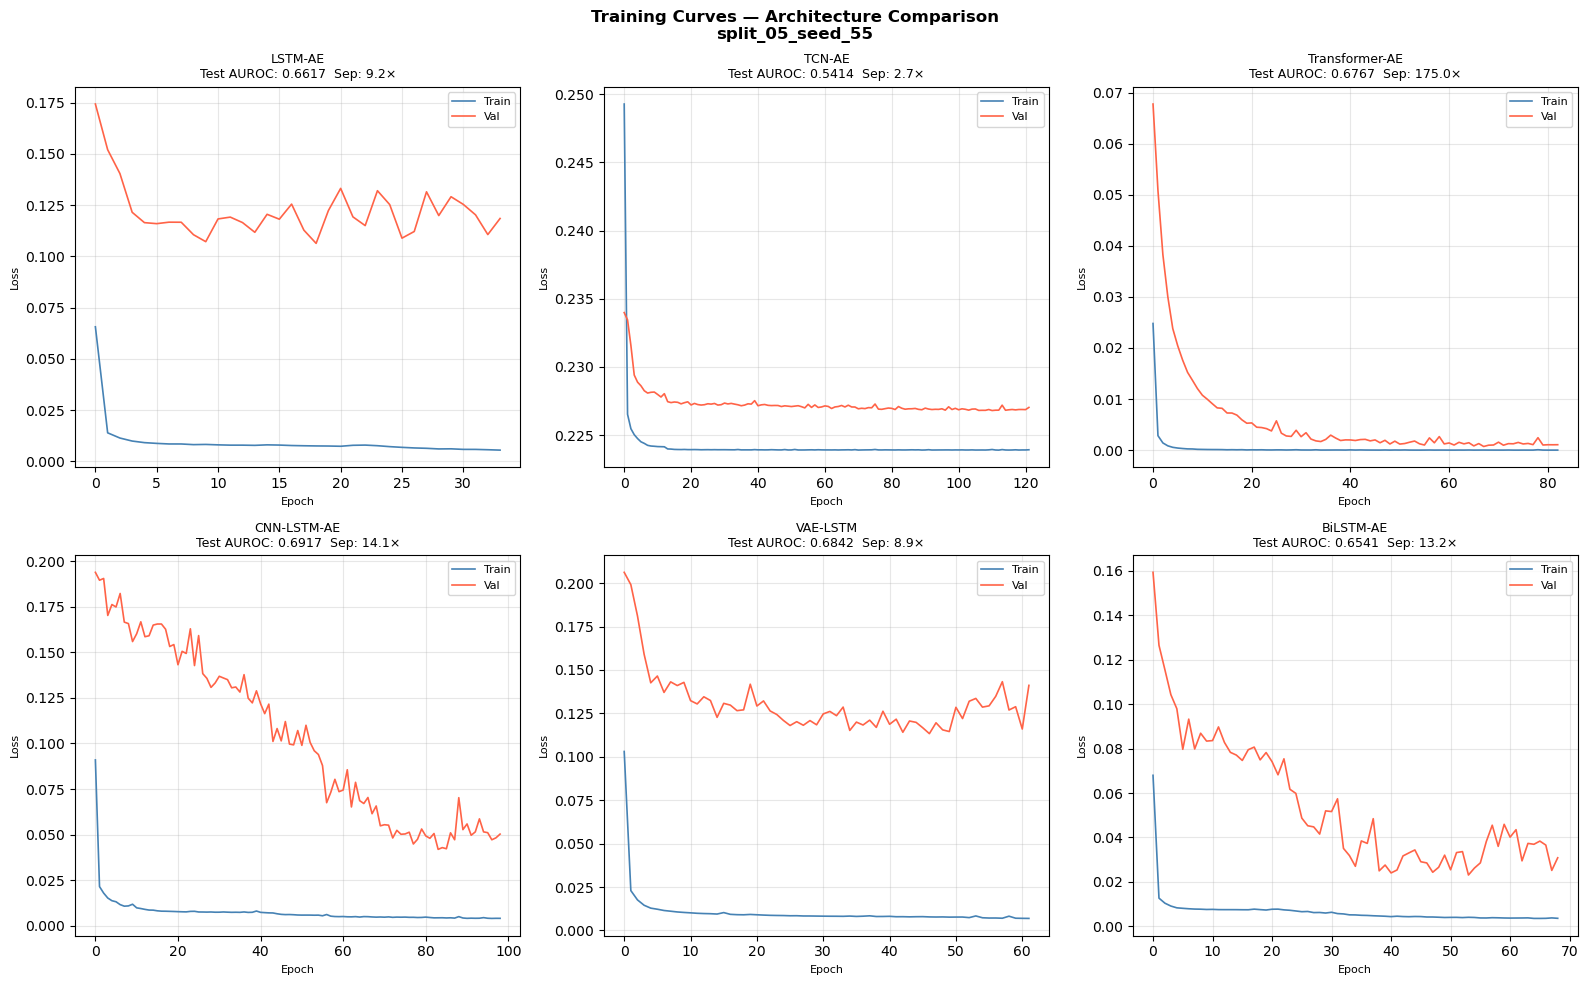

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/architecture_comparison_v3_voltage_random10_issue_flight-removed/training_curves_comparison.png


In [18]:
n_models = len(all_results)
n_cols   = 3
n_rows   = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(16, 5 * n_rows))
axes = axes.flat

fig.suptitle(
    f"Training Curves — Architecture Comparison\n{SPLIT_NAME}",
    fontsize=12, fontweight="bold"
)

for ax, (arch_name, res) in zip(axes, all_results.items()):
    ax.plot(res["train_losses"], color="steelblue",
            linewidth=1.2, label="Train")
    ax.plot(res["val_losses"],   color="tomato",
            linewidth=1.2, label="Val")
    ax.set_title(
        f"{arch_name}\n"
        f"Test AUROC: {res['test_auroc']:.4f}  "
        f"Sep: {res['test_sep_ratio']:.1f}×",
        fontsize=9
    )
    ax.set_xlabel("Epoch", fontsize=8)
    ax.set_ylabel("Loss",  fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide any unused axes
for ax in axes:
    ax.set_visible(False)

plt.tight_layout()
plot_path = OUTPUT_DIR / "training_curves_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

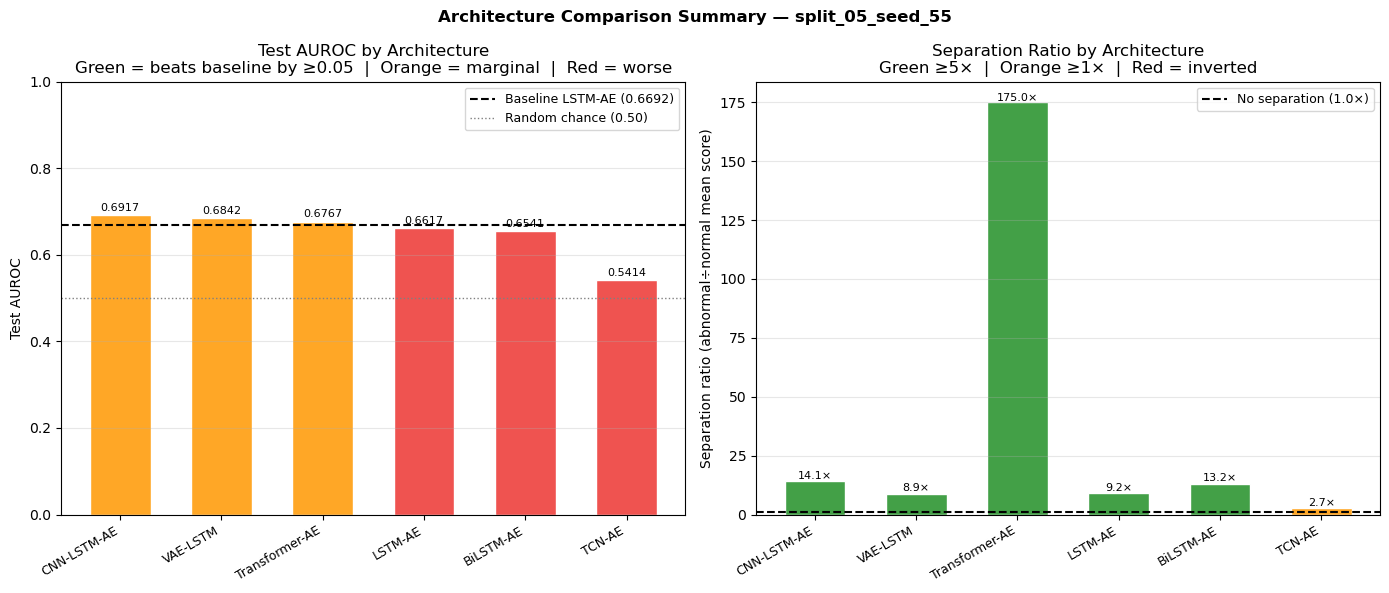

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/architecture_comparison_v3_voltage_random10_issue_flight-removed/auroc_comparison_chart.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    f"Architecture Comparison Summary — {SPLIT_NAME}",
    fontsize=12, fontweight="bold"
)

archs      = results_df["architecture"].tolist()
test_auroc = results_df["test_auroc"].tolist()
test_sep   = results_df["test_sep_ratio"].tolist()

colors = ["#43A047" if a >= BASELINE_AUROC + 0.05
          else "#FFA726" if a >= BASELINE_AUROC
          else "#EF5350"
          for a in test_auroc]

# Panel 1: Test AUROC
ax = axes[0]
bars = ax.bar(range(len(archs)), test_auroc,
              color=colors, width=0.6, edgecolor="white")
ax.axhline(BASELINE_AUROC, color="black", linestyle="--",
           linewidth=1.5, label=f"Baseline LSTM-AE ({BASELINE_AUROC})")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1,
           label="Random chance (0.50)")
for bar, val in zip(bars, test_auroc):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.005,
            f"{val:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(archs)))
ax.set_xticklabels(archs, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Test AUROC")
ax.set_title("Test AUROC by Architecture\n"
             "Green = beats baseline by ≥0.05  |  Orange = marginal  |  Red = worse")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim(0, 1.0)

# Panel 2: Separation ratio
ax = axes[1]
sep_colors = ["#43A047" if s >= 5 else "#FFA726" if s >= 1 else "#EF5350"
              for s in test_sep]
bars2 = ax.bar(range(len(archs)), test_sep,
               color=sep_colors, width=0.6, edgecolor="white")
ax.axhline(1.0, color="black", linestyle="--", linewidth=1.5,
           label="No separation (1.0×)")
for bar, val in zip(bars2, test_sep):
    ax.text(bar.get_x() + bar.get_width()/2,
            min(val, ax.get_ylim()[1] * 0.95) + 0.1,
            f"{val:.1f}×", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(archs)))
ax.set_xticklabels(archs, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Separation ratio (abnormal÷normal mean score)")
ax.set_title("Separation Ratio by Architecture\n"
             "Green ≥5×  |  Orange ≥1×  |  Red = inverted")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plot_path = OUTPUT_DIR / "auroc_comparison_chart.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")